# 02 — Phase 1: Baseline Signal-Only Classifier Under Domain Shift

Trains the plain signal-only ECG classifier on one PTB-XL site and
evaluates it, unmodified, on a different site — reproducing the
"domain shift hurts performance" problem from the reference paper
(proposal Section 6.2, step 1), before any fusion is introduced.

Assumes `00_colab_setup.ipynb` has already been run in this runtime.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive -maxdepth 3 -iname "*ptbxl*"

Mounted at /content/drive
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar


In [2]:
import os
REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"

if not os.path.exists("/content/mm-dg-healthcare"):
    !git clone {REPO_URL} /content/mm-dg-healthcare
%cd /content/mm-dg-healthcare
!pip install -q wfdb transformers pytest PyYAML tqdm scikit-learn pandas matplotlib

Cloning into '/content/mm-dg-healthcare'...
remote: Enumerating objects: 61, done.
remote: Counting objects: 100% (61/61), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 61 (delta 8), reused 46 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (61/61), 226.18 KiB | 1.22 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/mm-dg-healthcare
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.8 MB/s eta 0:00:00


In [3]:
!mkdir -p data/raw
!tar xf /content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar -C data/raw
!ls data/raw/ptbxl | head

ptbxl_database.csv
records100
robots.txt
scp_statements.csv


In [6]:
%cd /content/mm-dg-healthcare
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

/content/mm-dg-healthcare
GPU available: True
Tesla T4


## Run one domain pair from the command line

Uses `configs/baseline_signal_only.yaml` as-is (site 1 → site 2). This
calls the exact same `src/training/trainer.py` used outside Colab —
nothing Colab-specific about the actual training code, only this
notebook's setup cells are Colab-specific.

In [7]:
!python -m src.training.trainer --config configs/baseline_signal_only.yaml

Device: cuda
Domain split on 'site': train=[1] (n=6242), test=[2] (n=5019)
[epoch 0] train_loss=1.1002 test_loss=1.0728 acc=0.597 macro_f1=0.449 rare[4]: F1=0.120 P=0.290 R=0.075
[epoch 1] train_loss=0.8969 test_loss=0.9779 acc=0.624 macro_f1=0.499 rare[4]: F1=0.252 P=0.422 R=0.180
[epoch 2] train_loss=0.8432 test_loss=0.9985 acc=0.633 macro_f1=0.496 rare[4]: F1=0.118 P=0.500 R=0.067
[epoch 3] train_loss=0.8011 test_loss=0.9582 acc=0.638 macro_f1=0.503 rare[4]: F1=0.231 P=0.493 R=0.151
[epoch 4] train_loss=0.7796 test_loss=1.0567 acc=0.640 macro_f1=0.519 rare[4]: F1=0.253 P=0.519 R=0.167
[epoch 5] train_loss=0.7374 test_loss=0.9134 acc=0.663 macro_f1=0.548 rare[4]: F1=0.189 P=0.587 R=0.113
[epoch 6] train_loss=0.7137 test_loss=1.0075 acc=0.657 macro_f1=0.544 rare[4]: F1=0.212 P=0.574 R=0.130
[epoch 7] train_loss=0.6848 test_loss=0.9556 acc=0.660 macro_f1=0.563 rare[4]: F1=0.327 P=0.409 R=0.272
[epoch 8] train_loss=0.6767 test_loss=0.9264 acc=0.670 macro_f1=0.568 rare[4]: F1=0.290 P=0.5

## Inspect results

Every run's metrics, full epoch history, and the exact config used are
written to `experiments/results/<run_dir>/` — never just printed and
lost.

In [8]:
import json

run_dir = "experiments/results/baseline_signal_only_site1v2"
with open(f"{run_dir}/metrics.json") as f:
    metrics = json.load(f)
metrics

{'accuracy': 0.640964335525005,
 'macro_f1': 0.5367029193088948,
 'rare_class_labels': [0, 4],
 'rare_class_f1': 0.5509734241052998,
 'rare_class_precision': 0.5455302749823298,
 'rare_class_recall': 0.589098070826391,
 'per_class_f1': {'0': 0.7813361611876989,
  '1': 0.44550408719346046,
  '2': 0.5804382683057189,
  '3': 0.5556253928346951,
  '4': 0.32061068702290074}}

NameError: name 'plt' is not defined

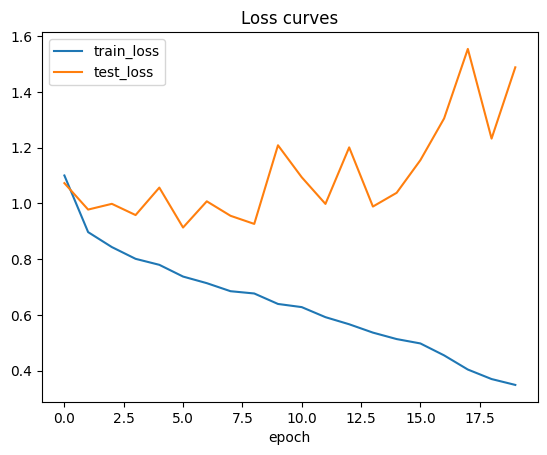

In [9]:
import pandas as pd

with open(f"{run_dir}/history.json") as f:
    history = json.load(f)

hist_df = pd.DataFrame([
    {"epoch": h["epoch"], "train_loss": h["train_loss"], "test_loss": h["test_loss"],
     "rare_class_f1": h["test_metrics"]["rare_class_f1"], "accuracy": h["test_metrics"]["accuracy"]}
    for h in history
])
hist_df.plot(x="epoch", y=["train_loss", "test_loss"], title="Loss curves")
plt.show()
hist_df.plot(x="epoch", y=["rare_class_f1", "accuracy"], title="Target-domain metrics per epoch")
plt.show()
hist_df.tail()

## Sweep every site pair (optional, matches the reference paper's full
across-trial validation table)

This trains one model per ordered site pair — with 5 PTB-XL sites that's
20 runs. On a Colab GPU each run is fast (small model, ~20 epochs), but
this cell will still take a while; run it when you actually want the full
table, not on every notebook re-run.

In [10]:
RUN_FULL_SWEEP = False  # flip to True when you want the full table

if RUN_FULL_SWEEP:
    import yaml
    from src.data.ptbxl_dataset import load_ptbxl_metadata
    from src.data.domain_split import all_pairwise_domain_splits
    from src.utils.config import load_config, save_config
    from src.training.trainer import train as train_fn

    metadata = load_ptbxl_metadata("data/raw/ptbxl")
    splits = all_pairwise_domain_splits(metadata, "site")

    results = []
    base_cfg_dict = load_config("configs/baseline_signal_only.yaml").to_dict()

    for split in splits:
        cfg_dict = dict(base_cfg_dict)
        cfg_dict["data"] = dict(cfg_dict["data"])
        cfg_dict["data"]["train_sites"] = split.train_domains
        cfg_dict["data"]["test_sites"] = split.test_domains
        run_name = f"baseline_site{split.train_domains[0]}v{split.test_domains[0]}"
        cfg_dict["output"] = {"run_dir": f"experiments/results/{run_name}"}

        from src.utils.config import Config
        cfg = Config(cfg_dict)
        print(f"\n=== {split.summary()} ===")
        final_metrics = train_fn(cfg)
        results.append({"train_site": split.train_domains[0], "test_site": split.test_domains[0], **final_metrics})

    sweep_df = pd.DataFrame(results)
    sweep_df.to_csv("experiments/results/baseline_sweep_summary.csv", index=False)
    sweep_df

Continue to `03_rare_class_identification.ipynb` to formally identify the rare class per Definition 2.

In [11]:
!cp -r experiments/results /content/drive/MyDrive/mm-dg-healthcare-data/results_backup